# Modèle Perceptron

Ce notebook contient l'implémentation et l'évaluation du modèle Perceptron pour prédire l'attrition des employés.

## Introduction au Perceptron

### Qu'est-ce qu'un Perceptron ?

Le **Perceptron** est l'un des algorithmes d'apprentissage automatique les plus anciens et les plus fondamentaux, inventé par Frank Rosenblatt en 1957. Il s'agit d'un classificateur binaire linéaire, c'est-à-dire qu'il peut séparer deux classes de données en traçant une ligne (ou un hyperplan en dimensions supérieures) entre elles.

Le Perceptron est considéré comme la brique de base des réseaux de neurones modernes. Bien qu'il soit relativement simple, il pose les fondations conceptuelles pour comprendre les architectures plus complexes comme les réseaux de neurones profonds.

### Fonctionnement mathématique

Le Perceptron fonctionne selon les principes suivants :

1. **Combinaison linéaire** : Pour chaque observation, le modèle calcule une somme pondérée des caractéristiques :
   $$z = w_1x_1 + w_2x_2 + ... + w_nx_n + b = \mathbf{w}^T\mathbf{x} + b$$
   
   où :
   - $\mathbf{x} = (x_1, x_2, ..., x_n)$ sont les caractéristiques d'entrée
   - $\mathbf{w} = (w_1, w_2, ..., w_n)$ sont les poids appris
   - $b$ est le biais (intercept)

2. **Fonction d'activation** : Le résultat est ensuite passé à travers une fonction d'activation (signe) :
   $$\hat{y} = \begin{cases} 1 & \text{si } z \geq 0 \\ 0 & \text{si } z < 0 \end{cases}$$

3. **Règle d'apprentissage** : Les poids sont mis à jour itérativement selon la règle :
   $$w_i := w_i + \eta \cdot (y - \hat{y}) \cdot x_i$$
   
   où $\eta$ est le taux d'apprentissage et $(y - \hat{y})$ est l'erreur de prédiction.

### Quelques images pour illuster ce propos

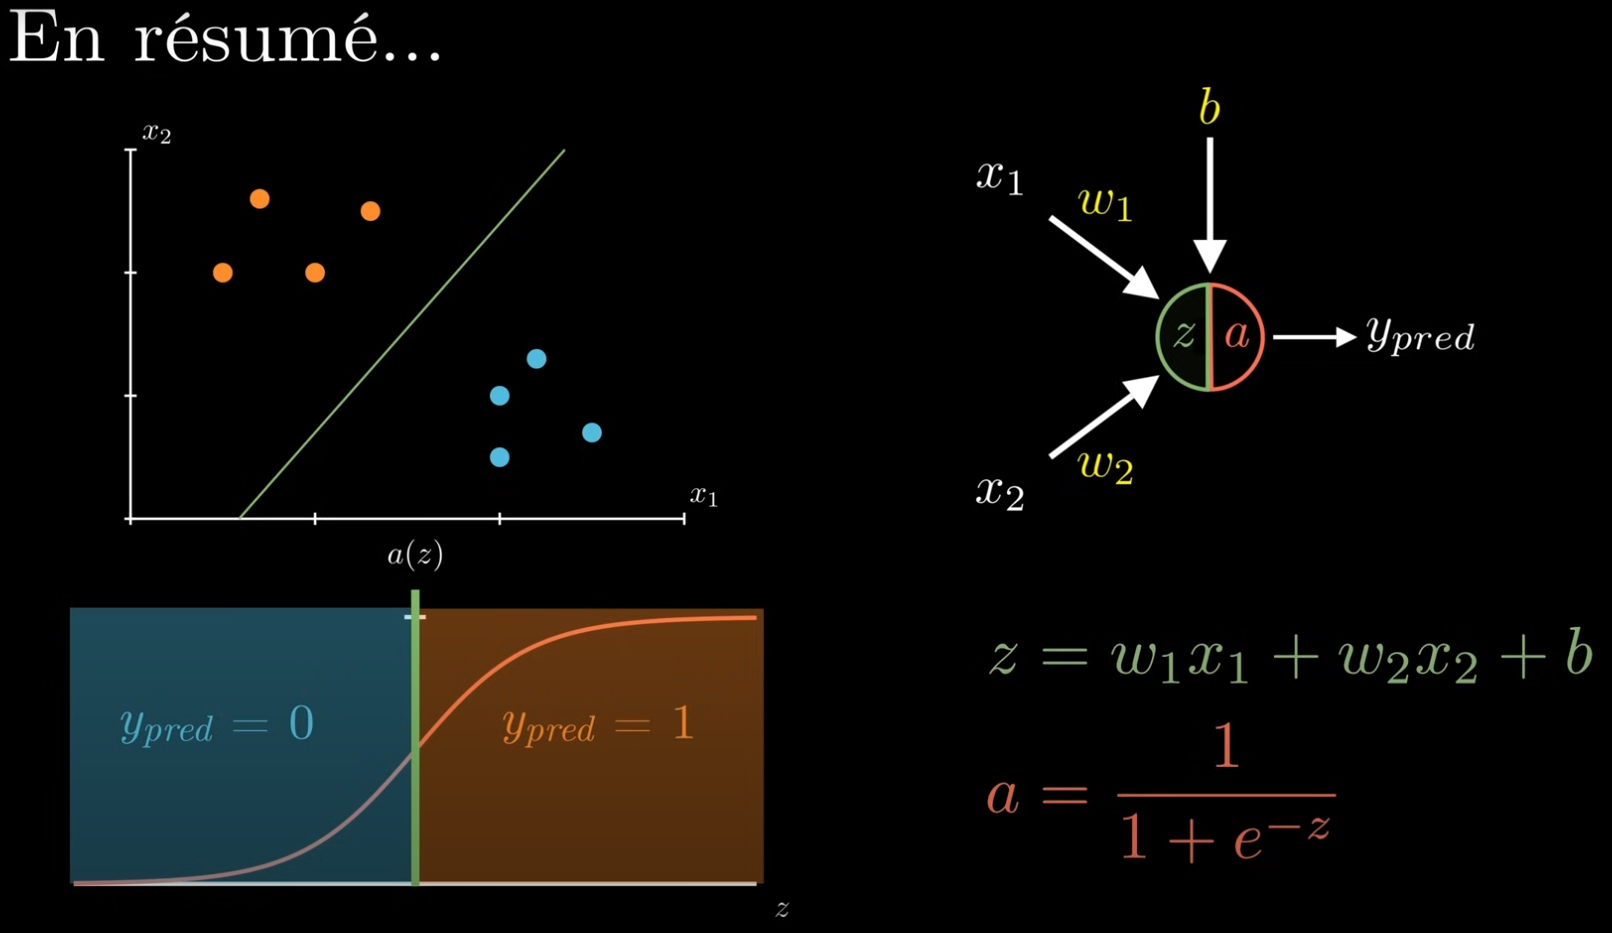

### Avantages du Perceptron

**Simplicité** : Algorithme facile à comprendre et à implémenter  
**Rapidité** : Entraînement très rapide, même sur de grands ensembles de données  
**Interprétabilité** : Les poids peuvent être interprétés directement  
**Efficacité mémoire** : Peu de paramètres à stocker  
**Adapté au temps réel** : Peut être mis à jour en ligne (online learning)

### Limitations

**Linéarité** : Ne peut classifier que des données linéairement séparables  
**Sensibilité** : Sensible aux valeurs aberrantes et à la normalisation  
**Pas de probabilités** : Ne fournit pas d'estimations probabilistes  
**Convergence** : Peut ne pas converger si les données ne sont pas linéairement séparables

### Application à la prédiction d'attrition

Dans notre contexte, nous utilisons le Perceptron pour prédire si un employé va quitter l'entreprise (attrition = 1) ou rester (attrition = 0). Le modèle apprendra à identifier une frontière de décision linéaire basée sur les caractéristiques des employés telles que :
- La satisfaction au travail
- Le niveau de salaire
- Les années dans l'entreprise
- L'équilibre vie professionnelle/vie privée
- Et autres facteurs démographiques et professionnels

**Note sur les schémas** : Pour une meilleure compréhension, vous pouvez ajouter :
- Un schéma d'un neurone perceptron avec les entrées, poids et fonction d'activation
- Une visualisation 2D d'une frontière de décision linéaire séparant deux classes
- Un diagramme montrant le processus d'apprentissage itératif

## 1. Importation des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve
import pickle

## 2. Chargement des données préparées

In [2]:
# Charger les données préparées
data = pd.read_csv('Data/prepared_data.csv')

# Séparer les caractéristiques et la cible
X = data.drop(columns=["Attrition", "EmployeeID"])
y = data['Attrition']

print(f"Shape des features: {X.shape}")
print(f"Shape de la cible: {y.shape}")
print(f"\nDistribution de la cible:\n{y.value_counts()}")

Shape des features: (4410, 45)
Shape de la cible: (4410,)

Distribution de la cible:
Attrition
0    3699
1     711
Name: count, dtype: int64


## 3. Séparation des données

In [3]:
# Séparation train/test (70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Taille ensemble d'entraînement: {X_train.shape[0]}")
print(f"Taille ensemble de test: {X_test.shape[0]}")

Taille ensemble d'entraînement: 3087
Taille ensemble de test: 1323


## 4. Entraînement du modèle Perceptron

### 🎯 Processus d'entraînement

L'entraînement du Perceptron est un processus **itératif** qui ajuste progressivement les poids du modèle pour minimiser les erreurs de classification.

#### **Algorithme d'apprentissage :**

**Initialisation :**
- Les poids $\mathbf{w} = (w_1, w_2, ..., w_n)$ sont initialisés aléatoirement (ou à zéro)
- Le biais $b$ est initialisé à 0

**Pour chaque itération (epoch) :**

1. **Parcourir** toutes les observations d'entraînement $(\mathbf{x}^{(i)}, y^{(i)})$

2. **Calculer** la prédiction :
   $$z^{(i)} = \mathbf{w}^T \mathbf{x}^{(i)} + b = \sum_{j=1}^{n} w_j x_j^{(i)} + b$$
   
   $$\hat{y}^{(i)} = \begin{cases} 1 & \text{si } z^{(i)} \geq 0 \\ 0 & \text{si } z^{(i)} < 0 \end{cases}$$

3. **Mettre à jour** les poids si l'erreur existe $(y^{(i)} \neq \hat{y}^{(i)})$ :
   $$w_j := w_j + \eta \cdot (y^{(i)} - \hat{y}^{(i)}) \cdot x_j^{(i)} \quad \forall j$$
   $$b := b + \eta \cdot (y^{(i)} - \hat{y}^{(i)})$$
   
   où $\eta$ est le **taux d'apprentissage** (learning rate)

4. **Répéter** jusqu'à convergence ou nombre maximum d'itérations

#### **Exemple concret avec nos données d'attrition :**

Imaginez un employé avec ces caractéristiques simplifiées :
- $x_1$ = `JobSatisfaction` = 2 (sur échelle 1-4, normalisé)
- $x_2$ = `YearsAtCompany` = 1 (peu d'ancienneté)
- $x_3$ = `MonthlyIncome` = 2500 (normalisé)
- $x_4$ = `OverTime` = 1 (fait des heures supplémentaires)
- $y$ = 1 (l'employé **part** effectivement)

**Itération 1 :** Poids initiaux aléatoires $w = [0.1, -0.2, 0.05, 0.3]$, $b = 0$

$$z = (0.1)(2) + (-0.2)(1) + (0.05)(2500) + (0.3)(1) + 0 = 125.3$$

Comme $z > 0$ → $\hat{y} = 1$ **Prédiction correcte !**  
Pas de mise à jour des poids.

**Itération 2 :** Autre employé avec $y = 0$ (reste) mais prédit $\hat{y} = 1$ 

Erreur = $y - \hat{y} = 0 - 1 = -1$

Mise à jour (avec $\eta = 0.01$) :
$$w_1 := 0.1 + 0.01 \times (-1) \times 2 = 0.08$$
$$w_2 := -0.2 + 0.01 \times (-1) \times 1 = -0.21$$

Les poids sont ajustés pour **réduire** l'activation quand les caractéristiques indiquent un départ mais l'employé reste.

#### **Dans notre contexte :**

Avec **{X_train.shape[1]} caractéristiques** (satisfaction, salaire, ancienneté, etc.) et **{X_train.shape[0]} employés d'entraînement**, le Perceptron va :

1. Apprendre quelles caractéristiques (poids élevés) sont les plus discriminantes pour prédire l'attrition
2. Trouver une **frontière de décision linéaire** qui sépare au mieux les employés qui partent de ceux qui restent
3. S'arrêter après un nombre maximum d'itérations (défini dans scikit-learn)

Lançons l'entraînement :

In [4]:
# Initialisation et entraînement du modèle
perceptron = Perceptron(random_state=42)
perceptron.fit(X_train, y_train)

print("Modèle entraîné avec succès!")

Modèle entraîné avec succès!


## 5. Prédictions

### Comment le modèle prédit-il ?

Une fois entraîné, le Perceptron utilise les poids appris pour classifier de nouveaux employés.

#### **Processus de prédiction :**

Pour un nouvel employé avec des caractéristiques $\mathbf{x}_{\text{new}} = (x_1, x_2, ..., x_n)$ :

**Étape 1 : Calcul du score de décision**
$$z = \mathbf{w}^T \mathbf{x}_{\text{new}} + b = w_1x_1 + w_2x_2 + ... + w_nx_n + b$$

**Étape 2 : Application de la fonction de décision**
$$\hat{y} = \begin{cases} 
1 \, (\text{Attrition}) & \text{si } z \geq 0 \\ 
0 \, (\text{Reste}) & \text{si } z < 0 
\end{cases}$$

**Interprétation géométrique :**
- La valeur $z$ représente la **distance signée** de l'employé par rapport à la frontière de décision
- $z > 0$ : l'employé est du côté "attrition" de la frontière → prédiction = **1**
- $z < 0$ : l'employé est du côté "reste" de la frontière → prédiction = **0**
- Plus $|z|$ est grand, plus le modèle est "confiant" dans sa prédiction

#### **Exemple concret de prédiction :**

Supposons que le modèle a appris ces poids après l'entraînement :

- $w_{\text{JobSatisfaction}}$ = -0.45 (plus de satisfaction → moins d'attrition)
- $w_{\text{YearsAtCompany}}$ = -0.30 (plus d'ancienneté → moins d'attrition)
- $w_{\text{MonthlyIncome}}$ = -0.0002 (salaire plus élevé → moins d'attrition)
- $w_{\text{OverTime}}$ = 0.60 (heures sup → plus d'attrition)
- $w_{\text{WorkLifeBalance}}$ = -0.35 (meilleur équilibre → moins d'attrition)
- $b$ = 0.2

**Cas 1 : Employé à risque de départ**
- JobSatisfaction = 1 (faible)
- YearsAtCompany = 0.5 (peu d'ancienneté)
- MonthlyIncome = 3000
- OverTime = 1 (oui)
- WorkLifeBalance = 1 (mauvais)

$$z = (-0.45)(1) + (-0.30)(0.5) + (-0.0002)(3000) + (0.60)(1) + (-0.35)(1) + 0.2$$
$$z = -0.45 - 0.15 - 0.6 + 0.60 - 0.35 + 0.2 = -0.75$$

$z < 0$ mais proche de 0 → Le modèle hésite, mais prédit **0 (Reste)**

**Cas 2 : Employé satisfait**
- JobSatisfaction = 4 (élevé)
- YearsAtCompany = 5 (ancienneté)
- MonthlyIncome = 8000
- OverTime = 0 (non)
- WorkLifeBalance = 4 (excellent)

$$z = (-0.45)(4) + (-0.30)(5) + (-0.0002)(8000) + (0.60)(0) + (-0.35)(4) + 0.2$$
$$z = -1.8 - 1.5 - 1.6 + 0 - 1.4 + 0.2 = -6.1$$

$z \ll 0$ → Score très négatif, le modèle prédit avec **forte confiance** : **0 (Reste)**

#### **Application sur l'ensemble de test :**

Nous allons maintenant appliquer ce processus de prédiction sur les **{X_test.shape[0]} employés** de notre ensemble de test pour évaluer les performances du modèle.

In [5]:
# Prédictions sur l'ensemble de test
y_pred = perceptron.predict(X_test)

print("Prédictions effectuées!")

Prédictions effectuées!


## 6. Évaluation du modèle

### Méthodologie d'évaluation

L'évaluation d'un modèle de classification est cruciale pour comprendre ses performances réelles et ses limites. Dans le cadre de la prédiction d'attrition, il ne suffit pas de regarder simplement le taux de précision globale, car notre dataset est déséquilibré (plus d'employés restent que partent).

Nous utiliserons plusieurs métriques et outils complémentaires pour évaluer notre modèle Perceptron :

#### **1. Matrice de Confusion**

La matrice de confusion est un tableau 2x2 qui résume les prédictions :

|                    | **Prédit : Reste (0)** | **Prédit : Part (1)** |
|--------------------|------------------------|------------------------|
| **Réel : Reste (0)** | **TN** (Vrais Négatifs) | **FP** (Faux Positifs) |
| **Réel : Part (1)**  | **FN** (Faux Négatifs)  | **TP** (Vrais Positifs) |

- **TN (True Negatives)** : Employés prédits comme restant et qui restent effectivement
- **TP (True Positives)** : Employés prédits comme partant et qui partent effectivement
- **FP (False Positives)** : Employés prédits comme partant mais qui restent (Erreur de Type I)
- **FN (False Negatives)** : Employés prédits comme restant mais qui partent (Erreur de Type II)

**Outil utilisé** : `confusion_matrix()` de scikit-learn + visualisation avec `seaborn.heatmap()`

#### **2. Rapport de Classification**

Le rapport de classification fournit plusieurs métriques détaillées pour chaque classe :

- **Précision (Precision)** : Parmi les employés prédits comme partant, combien partent réellement ?
  $$\text{Precision} = \frac{TP}{TP + FP}$$
  
- **Rappel (Recall/Sensitivity)** : Parmi les employés qui partent réellement, combien avons-nous détecté ?
  $$\text{Recall} = \frac{TP}{TP + FN}$$
  
- **F1-Score** : Moyenne harmonique entre précision et rappel (utile pour les datasets déséquilibrés)
  $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$
  
- **Support** : Nombre d'occurrences réelles de chaque classe dans les données de test

**Outil utilisé** : `classification_report()` de scikit-learn

#### **3. Score AUC-ROC**

L'**AUC-ROC** (Area Under the Receiver Operating Characteristic Curve) mesure la capacité du modèle à distinguer entre les deux classes :

- **AUC = 1.0** : Modèle parfait (sépare parfaitement les deux classes)
- **AUC = 0.5** : Modèle aléatoire (pas mieux qu'un tirage à pile ou face)
- **AUC < 0.5** : Modèle pire qu'un choix aléatoire

Ce score est particulièrement utile car il est **insensible au déséquilibre des classes**.

**Outil utilisé** : `roc_auc_score()` de scikit-learn

#### **4. Courbe ROC**

La courbe ROC (Receiver Operating Characteristic) visualise le compromis entre :
- **Taux de Vrais Positifs (TPR)** ou Recall : $\frac{TP}{TP + FN}$
- **Taux de Faux Positifs (FPR)** : $\frac{FP}{FP + TN}$

Plus la courbe est proche du coin supérieur gauche, meilleur est le modèle. Une courbe sur la diagonale représente un classifieur aléatoire.

**Outil utilisé** : `roc_curve()` de scikit-learn + visualisation avec `matplotlib`

#### **Pourquoi utiliser plusieurs métriques ?**

Chaque métrique révèle un aspect différent de la performance :

1. **Précision globale** peut être trompeuse avec des classes déséquilibrées
2. **Rappel** est crucial si manquer un départ d'employé est coûteux pour l'entreprise
3. **Précision** est importante si on veut éviter de fausses alarmes
4. **F1-Score** équilibre précision et rappel
5. **AUC-ROC** donne une vue d'ensemble de la capacité discriminante du modèle

**Dans notre contexte d'attrition**, un **FN (Faux Négatif)** peut être plus coûteux qu'un **FP (Faux Positif)** : il vaut mieux identifier par erreur un employé à risque qui finalement reste, que de manquer un employé qui va réellement partir.

Passons maintenant à l'évaluation détaillée de notre modèle Perceptron :

### 6.1 Matrice de confusion

Matrice de Confusion (Perceptron) :
 [[1015  100]
 [ 140   68]]


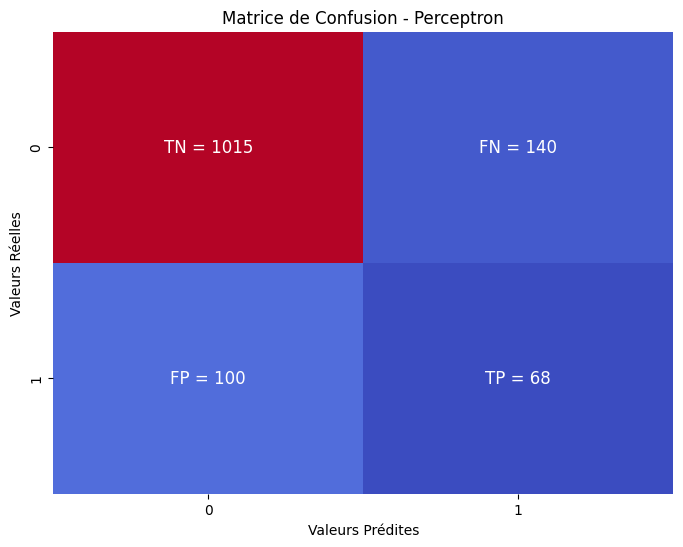

In [6]:
# Matrice de confusion
conf_matrix = confusion_matrix(y_test, y_pred)
print("Matrice de Confusion (Perceptron) :\n", conf_matrix)

# Visualisation
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=False, fmt="d", cmap="coolwarm", cbar=False)

# Calcul des valeurs TP, TN, FP, FN
TN, FP, FN, TP = conf_matrix.ravel()

# Ajout des valeurs sur le graphique
plt.text(0.5, 0.5, f'TN = {TN}', ha='center', va='center', color='white', fontsize=12)
plt.text(0.5, 1.5, f'FP = {FP}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 0.5, f'FN = {FN}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 1.5, f'TP = {TP}', ha='center', va='center', color='white', fontsize=12)
plt.title("Matrice de Confusion - Perceptron")
plt.ylabel('Valeurs Réelles')
plt.xlabel('Valeurs Prédites')
plt.show()

### 6.2 Rapport de classification

In [7]:
# Rapport de classification
class_report = classification_report(y_test, y_pred)
print("Rapport de Classification (Perceptron) :\n", class_report)

Rapport de Classification (Perceptron) :
               precision    recall  f1-score   support

           0       0.88      0.91      0.89      1115
           1       0.40      0.33      0.36       208

    accuracy                           0.82      1323
   macro avg       0.64      0.62      0.63      1323
weighted avg       0.80      0.82      0.81      1323



### 6.3 Score AUC-ROC

In [8]:
# AUC-ROC
roc_auc = roc_auc_score(y_test, y_pred)
print(f"AUC-ROC (Perceptron) : {roc_auc:.4f}")

AUC-ROC (Perceptron) : 0.6186


### 6.4 Courbe ROC

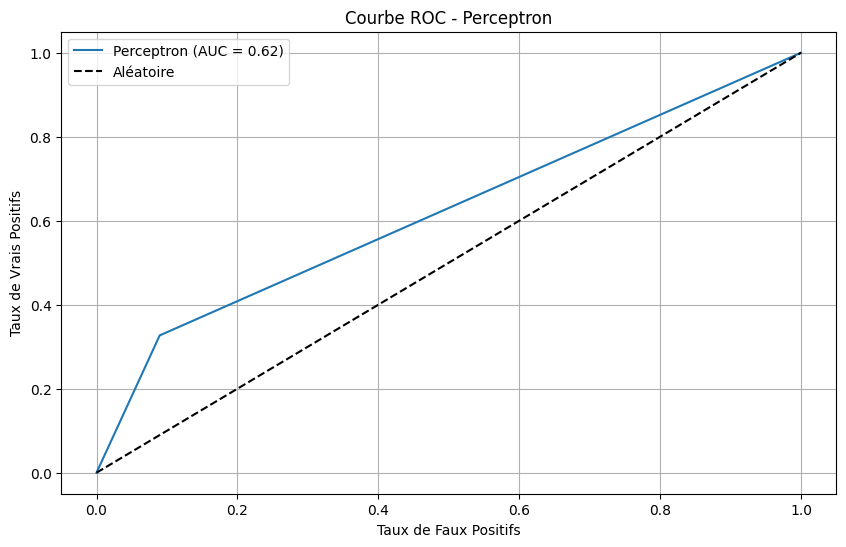

In [9]:
# Courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_pred)

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f"Perceptron (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="Aléatoire")
plt.xlabel("Taux de Faux Positifs")
plt.ylabel("Taux de Vrais Positifs")
plt.title("Courbe ROC - Perceptron")
plt.legend()
plt.grid(True)
plt.show()

## 7. Sauvegarde du modèle et des résultats

In [10]:
# Sauvegarde du modèle
with open('Data/perceptron_model.pkl', 'wb') as f:
    pickle.dump(perceptron, f)

# Sauvegarde des résultats
results = {
    'model_name': 'Perceptron',
    'predictions': y_pred,
    'auc_roc': roc_auc,
    'confusion_matrix': conf_matrix
}

with open('Data/perceptron_results.pkl', 'wb') as f:
    pickle.dump(results, f)

print("Modèle et résultats sauvegardés!")

Modèle et résultats sauvegardés!


## Résumé

Ce notebook a permis de :
1. Charger les données préparées
2. Entraîner un modèle Perceptron
3. Évaluer ses performances avec plusieurs métriques
4. Sauvegarder le modèle et les résultats pour comparaison ultérieure